# Iterators & Generators

A `for` loop works with lists, strings, files and many other objects. The common mechanism behind them is the **iterator protocol**. **Generators** are the simplest way to create iterators. They produce values one at a time, so they can process data that does not fit in memory.

**After this lesson you can:**

1. Explain iterables, iterators, `iter()` and `next()`.
2. Write generator functions with `yield` and `yield from`.
3. Build lazy data pipelines with generators and `itertools`.
4. Measure the memory benefit of lazy evaluation.

## 1. Iterables and Iterators

- An **iterable** can give an iterator: `iter(obj)` works. Examples: list, str, dict, file.
- An **iterator** returns the next value with `next(it)` and raises `StopIteration` at the end.

A `for` loop calls `iter()` once, then `next()` until `StopIteration`.

In [1]:
colors = ["red", "green", "blue"]
it = iter(colors)
print(next(it), next(it), next(it))
try:
    next(it)
except StopIteration:
    print("StopIteration: the iterator is exhausted")

# What a for loop does internally
it = iter(colors)
while True:
    try:
        c = next(it)
    except StopIteration:
        break
    print("loop item:", c)

red green blue
StopIteration: the iterator is exhausted
loop item: red
loop item: green
loop item: blue


## 2. A Custom Iterator Class

A class becomes an iterator when it defines `__iter__` (return itself) and `__next__` (return the next value or raise `StopIteration`).

In [2]:
class Countdown:
    def __init__(self, start: int):
        self.current = start

    def __iter__(self):
        return self

    def __next__(self) -> int:
        if self.current <= 0:
            raise StopIteration
        self.current -= 1
        return self.current + 1

print(list(Countdown(5)))

[5, 4, 3, 2, 1]


## 3. Generator Functions

A function that contains `yield` is a **generator function**. Calling it does not run the body; it returns a generator object. Each `next()` runs the body until the next `yield`, returns the value and **pauses** there. The local variables keep their values between calls.

The same countdown takes four lines as a generator.

In [3]:
def countdown(start: int):
    while start > 0:
        yield start
        start -= 1

gen = countdown(3)
print(type(gen).__name__, next(gen), next(gen), list(gen))

def fibonacci():
    """An infinite generator: it is safe because values are produced only on request."""
    a, b = 0, 1
    while True:
        yield a
        a, b = b, a + b

from itertools import islice
print("first 12 Fibonacci numbers:", list(islice(fibonacci(), 12)))

def flatten(nested):
    for item in nested:
        if isinstance(item, list):
            yield from flatten(item)      # delegate to a sub-generator
        else:
            yield item

print("flatten:", list(flatten([1, [2, [3, 4]], 5, [[6]]])))

generator 3 2 [1]
first 12 Fibonacci numbers: [0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89]
flatten: [1, 2, 3, 4, 5, 6]


## 4. Lazy Pipelines

Generators can be chained. Each stage pulls one value from the stage before it. No stage builds a full list, so memory use stays small even for very large inputs. The example processes a log file of 200,000 lines (synthetic) and finds the slowest endpoints.

In [4]:
import random
import tempfile
from collections import Counter
from itertools import groupby
from pathlib import Path

random.seed(0)
log_file = Path(tempfile.mkdtemp()) / "access.log"
endpoints = ["/api/users", "/api/orders", "/api/search", "/health"]
with open(log_file, "w", encoding="utf-8") as f:
    for i in range(200_000):
        ep = random.choice(endpoints)
        ms = random.expovariate(1 / (300 if ep == "/api/search" else 40))
        status = 500 if random.random() < 0.01 else 200
        f.write(f"{i} {ep} {status} {ms:.1f}\n")

def read_lines(path):
    with open(path, encoding="utf-8") as f:
        yield from f

def parse(lines):
    for line in lines:
        _, ep, status, ms = line.split()
        yield ep, int(status), float(ms)

def slow(records, threshold_ms=500):
    return (r for r in records if r[2] > threshold_ms)

pipeline = slow(parse(read_lines(log_file)))
slow_by_endpoint = Counter(ep for ep, _, _ in pipeline)
print(f"log size: {log_file.stat().st_size / 1e6:.1f} MB")
print("requests slower than 500 ms:", dict(slow_by_endpoint))

# groupby works on sorted (or already grouped) data
statuses = sorted(status for _, status, _ in parse(read_lines(log_file)))
print("status counts:", {k: sum(1 for _ in g) for k, g in groupby(statuses)})

log size: 5.3 MB
requests slower than 500 ms: {'/api/search': 9329, '/api/orders': 1}
status counts: {200: 198033, 500: 1967}


## 5. Memory: List vs Generator

`tracemalloc` measures the peak memory that Python allocates. The experiment sums the squares of $n$ numbers, once with a list and once with a generator expression.

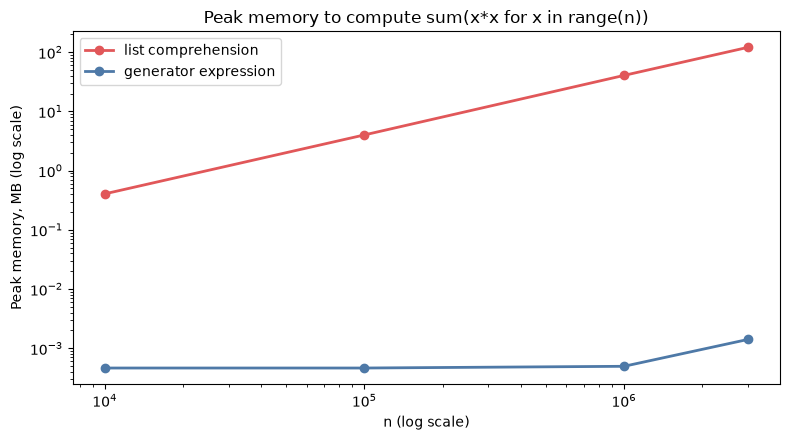

n =    10,000: list     0.40 MB | generator 0.0005 MB
n =   100,000: list     4.00 MB | generator 0.0005 MB
n = 1,000,000: list    40.45 MB | generator 0.0005 MB
n = 3,000,000: list   120.39 MB | generator 0.0014 MB


In [5]:
import tracemalloc

import matplotlib.pyplot as plt

def peak_memory(fn) -> float:
    tracemalloc.start()
    fn()
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1e6

sizes = [10_000, 100_000, 1_000_000, 3_000_000]
mem_list = [peak_memory(lambda n=n: sum([x * x for x in range(n)])) for n in sizes]
mem_gen = [peak_memory(lambda n=n: sum(x * x for x in range(n))) for n in sizes]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sizes, mem_list, marker="o", lw=2, color="#E15759", label="list comprehension")
ax.plot(sizes, mem_gen, marker="o", lw=2, color="#4E79A7", label="generator expression")
ax.set(xscale="log", yscale="log", title="Peak memory to compute sum(x*x for x in range(n))",
       xlabel="n (log scale)", ylabel="Peak memory, MB (log scale)")
ax.legend()
plt.tight_layout()
plt.show()
for n, a, b in zip(sizes, mem_list, mem_gen):
    print(f"n = {n:>9,}: list {a:8.2f} MB | generator {b:.4f} MB")

The list version needs memory in proportion to $n$: it stores all values before `sum()` starts. The generator version needs a constant, tiny amount of memory, whatever the value of $n$.

*Insight: Use a generator when you go through data once, in order, and the data is large or unbounded (files, database cursors, streams). Use a list when you need random access, the length, or several passes over the same values.*

## Real-World Use Case or Analogy

A list is like **buying a full box of water bottles** before a trip: you carry everything at once. A generator is like **a water tap**: you get one glass when you need it, and you never carry more than one glass.

Generators are everywhere in data and AI systems: reading a 50 GB file line by line, streaming rows from a database cursor, feeding batches to a neural network (PyTorch `DataLoader`, M20), and streaming tokens from an LLM to the user one by one (M30).